# 01 · Data ingestion: from the Kaggle file to a searchable product

This notebook runs the project's ingestion pipeline in memory, step by step, on the raw Amazon Product Dataset 2020,
and checks the result against the report that `voiceshop ingest` writes. It answers four questions:

1. What is in the file, and what is missing from it?
2. Which rows are kept, and why were the others dropped?
3. How are the fields the file does not have (brand, materials, a usable age) derived, and how is each derived value tied to the listing it came from?
4. What does one product look like when it reaches the search index?

The prose version is [docs/data.md](../docs/data.md); how the index is searched is in [docs/retrieval.md](../docs/retrieval.md).
The outputs below are saved with the notebook, so it can be read without the data. To run it again:

```bash
bash scripts/bootstrap_mac.sh          # once: the dataset from Kaggle into data/raw/, and the models
jupyter nbconvert --to notebook --execute --inplace notebooks/01_data_ingestion.ipynb
```

One rule runs through all of it: **nothing about a product is made up.** A value is copied from the listing, derived from
the listing's own words and labelled as derived, or left empty.

In [1]:
import json
import re
import warnings
from collections import Counter

warnings.filterwarnings("ignore")                       # progress-bar and deprecation notices from libraries

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FuncFormatter

from voiceshop.data import attributes as attr
from voiceshop.data import cleaning as cl
from voiceshop.data import derived, ingest, units
from voiceshop.paths import project_root

ROOT = project_root()
RAW_CSV = ROOT / "data" / "raw" / "amazon_product_dataset_2020.csv"
REPORT = json.loads((ROOT / "data" / "processed" / "ingest_report.json").read_text())   # written by `voiceshop ingest`
pd.set_option("display.max_colwidth", 120, "display.width", 220, "display.max_rows", 40)

<details><summary>Chart helpers (one hue for magnitudes, values at the bar tips, a table next to every chart)</summary>

Every chart below encodes a magnitude, so every chart uses one hue; where two groups are compared they take the
first two colours of a palette checked for colour-blind readers, and "nothing stated" is grey. Text is never coloured.
</details>

In [2]:
BLUE, ORANGE, TRACK, GREY = "#2a78d6", "#eb6834", "#cde2fb", "#c3c2b7"
INK, SECONDARY, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 9.5, "text.color": INK, "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": SECONDARY, "xtick.labelsize": 8.5, "ytick.labelsize": 9,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
})


def round_ends(ax, bars, radius_px: float = 4.0) -> None:
    # Each bar becomes one shape with a rounded data end and a square baseline (drawn once the axes have their final size).
    ax.figure.canvas.draw()
    (x0, y0), (x1, y1) = ax.transData.transform([(0, 0), (1, 1)])
    per_x, per_y = abs(x1 - x0), abs(y1 - y0)
    for bar in list(bars):
        x, y, w, h = bar.get_x(), bar.get_y(), bar.get_width(), bar.get_height()
        if w <= 0:
            bar.remove()
            continue
        rx, ry = min(radius_px / per_x, w), min(radius_px / per_y, h / 2)
        C, L = MplPath.CURVE3, MplPath.LINETO
        vertices = [(x, y), (x + w - rx, y), (x + w, y), (x + w, y + ry), (x + w, y + h - ry), (x + w, y + h), (x + w - rx, y + h), (x, y + h), (x, y)]
        ax.add_patch(PathPatch(MplPath(vertices, [MplPath.MOVETO, L, C, C, L, C, C, L, MplPath.CLOSEPOLY]), fc=bar.get_facecolor(), ec="none", zorder=bar.get_zorder()))
        bar.remove()


def hbars(values: pd.Series, title: str, fmt: str = "{:,.0f}", track: float | None = None, note: dict | None = None, width: float = 7.4) -> None:
    # Ranked horizontal bars in one hue, the value at each tip. `track` draws a lighter bar up to a common whole (a meter list);
    # `note` adds a remark per row in a column of its own.
    labels, numbers = [str(k) for k in values.index][::-1], list(values.values)[::-1]
    fig, ax = plt.subplots(figsize=(width, 0.32 * len(labels) + 0.9))
    limit = track or max(numbers)
    ax.set_xlim(0, limit * (1.75 if note else 1.14))
    ax.set_ylim(-0.6, len(labels) - 0.4)
    if track is not None:
        round_ends(ax, ax.barh(labels, [track] * len(labels), height=0.5, color=TRACK, zorder=1))
    round_ends(ax, ax.barh(labels, numbers, height=0.5, color=BLUE, zorder=2))
    for i, (label, number) in enumerate(zip(labels, numbers)):
        ax.text((track if track is not None else number) + limit * 0.012, i, fmt.format(number), va="center", ha="left", color=INK, fontsize=9)
        if note and label in note:
            ax.text(limit * 1.15, i, note[label], va="center", ha="left", color=SECONDARY, fontsize=8.5)
    ax.set_title(title, pad=10)
    ax.set_yticks(range(len(labels)), labels)
    ax.tick_params(length=0)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)
    plt.show()


def segments(parts: list[tuple[str, float, str]], title: str, width: float = 7.4) -> None:
    # One whole split into parts: a single bar, each part its own block with its label inside when the label fits.
    total = sum(value for _, value, _ in parts)
    fig, ax = plt.subplots(figsize=(width, 0.95))
    fig.subplots_adjust(left=0.01, right=0.99)
    ax.set_xlim(0, total)
    ax.set_ylim(-0.75, 0.75)
    gap, left = total * 0.003, 0.0
    renderer = fig.canvas.get_renderer()
    for label, value, colour in parts:
        ax.barh(0, value - gap, left=left + gap / 2, height=0.62, color=colour, zorder=2)
        text = ax.text(left + value / 2, 0, label, ha="center", va="center", color=INK if colour == GREY else "#ffffff", fontsize=9)
        fig.canvas.draw()
        box = text.get_window_extent(renderer).transformed(ax.transData.inverted())
        if box.width > value * 0.92:                         # a label that does not fit is not drawn; the title and the table carry it
            text.remove()
        left += value
    ax.axis("off")
    ax.set_title(title, pad=2)
    plt.show()

## 1. The file

One CSV from Kaggle (PromptCloud, CC0), crawled in January 2020. Every price in the catalog is therefore a January 2020 price.

10,002 rows, 28 columns


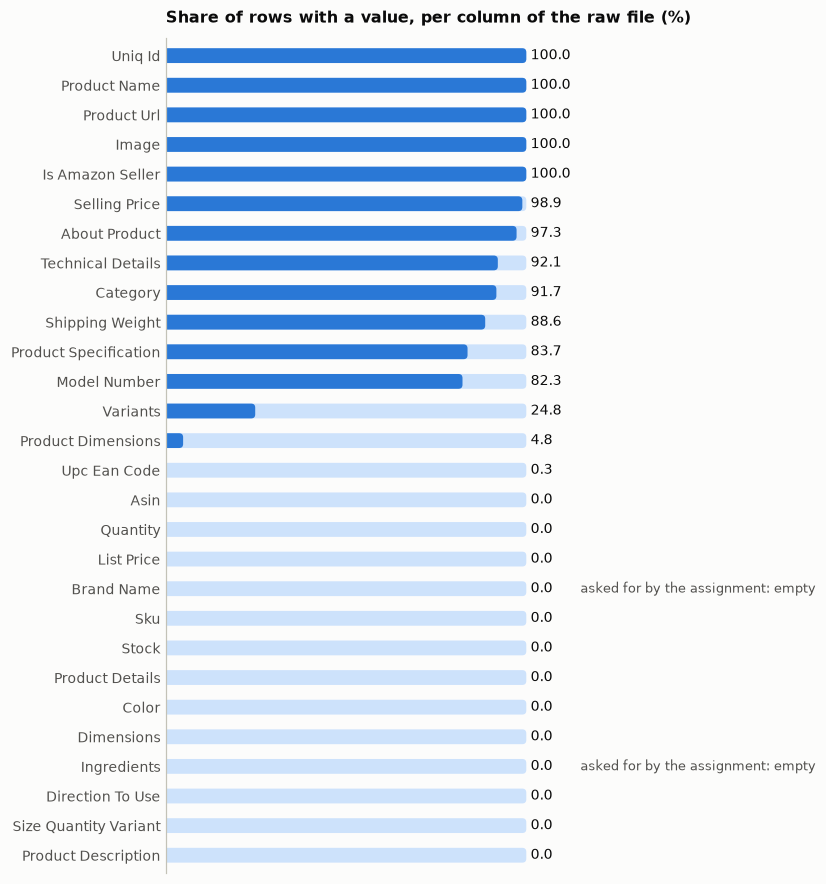

13 of 28 columns are empty in every row: Asin, Quantity, List Price, Brand Name, Sku, Stock, Product Details, Color, Dimensions, Ingredients, Direction To Use, Size Quantity Variant, Product Description
There is no rating column and no review column at all.


In [3]:
raw = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=True)
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
fill = raw.notna().mean().mul(100).round(1).sort_values(ascending=False)
asked_for = {"Brand Name": "asked for by the assignment: empty", "Ingredients": "asked for by the assignment: empty"}
hbars(fill, "Share of rows with a value, per column of the raw file (%)", fmt="{:.1f}", track=100, note=asked_for)
print(f"{(fill == 0).sum()} of {len(fill)} columns are empty in every row: {', '.join(fill[fill == 0].index)}")
print("There is no rating column and no review column at all.")

The assignment asks for eight fields per product: `id, title, brand, category, price, rating, features, ingredients`.
Three of them are not in the data as given: **Brand Name** and **Ingredients** are empty columns, and there is no rating.
Sections 4 and 5 show what was done about brand and ingredients. Ratings stay empty: none are invented.

What a row looks like. The specification is one string from which the crawl removed the spaces, and the price cell is
free text:

In [4]:
example = raw[raw["Product Url"].str.contains("B000B9RHYC", na=False)].iloc[0]
for column in ["Product Name", "Category", "Selling Price", "Product Specification", "About Product"]:
    print(f"{column}:\n    {str(example[column])[:330]}\n")

Product Name:
    Melissa & Doug Safari Wooden Chunky Puzzle (Preschool, Chunky Wooden Pieces, Full-Color Pictures, 8 Pieces, Great Gift for Girls and Boys - Best for 2, 3, and 4 Year Olds)

Category:
    Toys & Games | Puzzles | Pegged Puzzles

Selling Price:
    $9.99

Product Specification:
    ProductDimensions:10.6x11.8x0.5inches|ItemWeight:1.1pounds|ShippingWeight:1.65pounds(Viewshippingratesandpolicies)|DomesticShipping:ItemcanbeshippedwithinU.S.|InternationalShipping:ThisitemcanbeshippedtoselectcountriesoutsideoftheU.S.LearnMore|ASIN:B000B9RHYC|Itemmodelnumber:3722|Manufacturerrecommendedage:24months-4years

About Product:
    Make sure this fits by entering your model number. | 8-PIECE WOODEN PUZZLE: The Melissa & Doug Safari Wooden Chunky Puzzle features 8 wooden, durable, easy-to-grasp pieces that display full-color pictures of safari animals. | CHUNKY WOODEN PIECES: Our puzzles for young kids include high-quality, chunky wooden pieces to ensure ti



## 2. The price cell, shape by shape

The price is the one field every answer of the assistant states, so every shape of the cell was looked at. The parser is
`cleaning.parse_price`. A price always opens its cell; a dollar amount further in is something else.

In [5]:
def price_shape(cell) -> str:
    if cl.is_missing(cell):
        return "empty"
    text = cl.normalize_text(cell)
    if not text.startswith("$"):
        return "not a price"
    if re.fullmatch(r"\$\d[\d,]*\.\d{1,2}", text):
        return "$12.34"
    if re.fullmatch(r"\$\d[\d,]*\.\d{2}\s*-\s*\$\d[\d,]*\.\d{2}", text):
        return "a range"
    if re.match(r"^\$\s*\d[\d,]*\s+\d{2}(\s|$)", text):
        return "dollars and cents apart"
    if re.match(r"^\$\d[\d,]*\.\d{1,2}\s+\$", text):
        return "rendered twice"
    return "other"


shape = raw["Selling Price"].map(price_shape)
rows = []
for name, count in shape.value_counts().items():
    cells_of_shape = raw.loc[shape == name, "Selling Price"].map(cl.normalize_text)
    sample = "" if name == "empty" else cells_of_shape.value_counts().index[0]
    rows.append({"shape": name, "rows": count, "most common cell": sample[:58], "parsed as (price, upper end)": cl.parse_price(sample) if sample else None})
display(pd.DataFrame(rows))
assert (shape == "other").sum() == 0                        # every cell has a known shape

,shape,rows,most common cell,"parsed as (price, upper end)"
0,$12.34,9510,$19.99,"(19.99, None)"
1,a range,229,$8.25 - $31.95,"(8.25, 31.95)"
2,empty,107,,None
3,rendered twice,94,$24.99 $24.99,"(24.99, None)"
4,not a price,56,Total price:,None
5,dollars and cents apart,6,$ 19 99 $39.95 #listPriceLegalMessageText { margin-left: 4,"(19.99, None)"


Two of these shapes were read wrongly until 12 November 2026, and were found by exactly this comparison of every cell with
what the parser returned. Dollars and cents apart, followed by the list price, lost the cents; and one cell that is not a
price at all contains a dollar amount.

In [6]:
for cell in ["$ 19 99 $39.95 #listPriceLegalMessageText { margin-left: 4px !important; }", "$ 12 63", "$6.94 $ 6 . 94",
             "$74.99 - $249.99", "Total price:", "FREE Shipping Get free shipping Free 5-8 business-day shipping within the U.S. when you order $25.00 of eligible items"]:
    print(f"{cell[:74]!r:<78} -> {cl.parse_price(cell)}")

'$ 19 99 $39.95 #listPriceLegalMessageText { margin-left: 4px !important; }'   -> (19.99, None)
'$ 12 63'                                                                      -> (12.63, None)
'$6.94 $ 6 . 94'                                                               -> (6.94, None)
'$74.99 - $249.99'                                                             -> (74.99, 249.99)
'Total price:'                                                                 -> None
'FREE Shipping Get free shipping Free 5-8 business-day shipping within the '   -> None


## 3. Curation: which rows are kept

A row is kept when it has a title, an ASIN, a usable price between \$0.50 and \$20,000 and at least 20 characters of
descriptive text, and is the first row for its ASIN. The cell below runs the whole pipeline (`ingest.ingest_frame`): the
same code as `voiceshop ingest`, with the cached model extraction of section 4 applied.

In [7]:
llm = derived.load_attributes(ROOT / "data" / "derived" / ingest.DERIVED_FILE)
products, report = ingest.ingest_frame(raw, llm)

meaning = {"no_price": "no usable price (empty, or not a price)", "no_description": "no descriptive text", "price_out_of_range": "price outside $0.50 to $20,000",
           "no_title": "no title", "duplicate_asin": "second row for the same ASIN"}
dropped = pd.DataFrame([{"reason": meaning[k], "rows": v} for k, v in report["rows_dropped"].items()])
display(dropped)
print(f"in the file {report['rows_in']:,}   dropped {dropped['rows'].sum():,}   kept {report['rows_kept']:,}")

# The numbers in docs/data.md come from the report that `voiceshop ingest` wrote; this run must reproduce it.
for key in ("rows_in", "rows_kept", "rows_dropped", "coverage_pct", "age", "brand_source", "ingredients_source", "llm_overlay"):
    assert report[key] == REPORT[key], key
print("identical to data/processed/ingest_report.json")

,reason,rows
0,"no usable price (empty, or not a price)",163
1,no descriptive text,95
2,"price outside $0.50 to $20,000",2
3,no title,1
4,second row for the same ASIN,1


in the file 10,002   dropped 262   kept 9,740
identical to data/processed/ingest_report.json


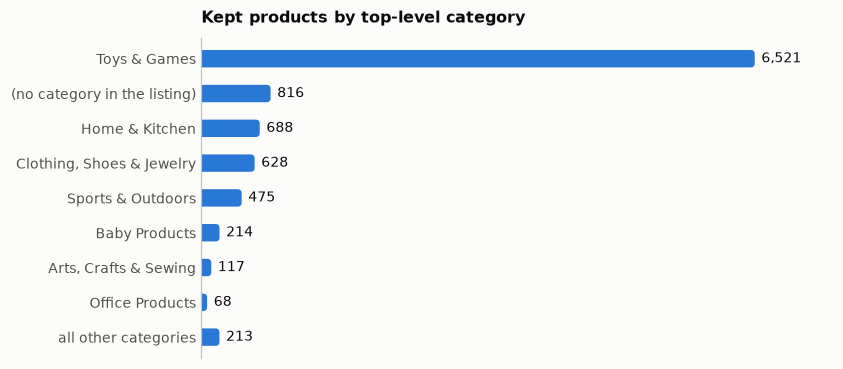

prices: $0.51 to $5,332, median $16.99; nine in ten are under $64.99


In [8]:
top = pd.Series(report["categories"]).rename({"(none)": "(no category in the listing)"})
hbars(pd.concat([top.head(8), pd.Series({"all other categories": top.iloc[8:].sum()})]), "Kept products by top-level category")
price = products["price"]
print(f"prices: ${price.min():.2f} to ${price.max():,.0f}, median ${price.median():.2f}; nine in ten are under ${price.quantile(0.9):.2f}")

Two thirds of the catalog is toys and games. It has no household cleaners: the assignment's own example request, a
stainless-steel cleaner, is answered from the live web, and the answer says so.

## 4. The eight required columns

`products.parquet` has 48 columns; these are the eight the assignment names, with the share of products that have a value.

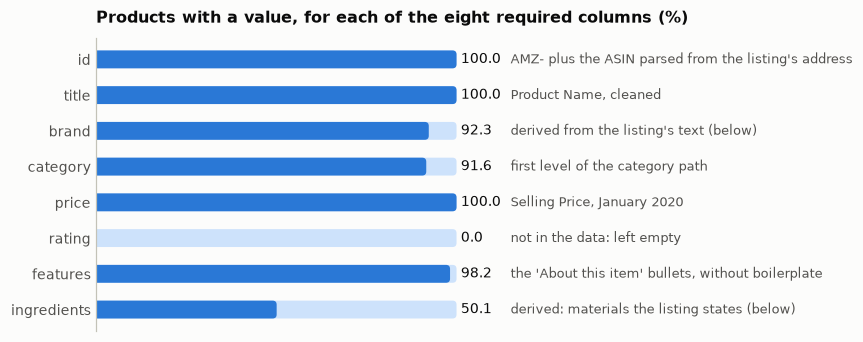

In [9]:
source = {
    "id": "AMZ- plus the ASIN parsed from the listing's address", "title": "Product Name, cleaned", "brand": "derived from the listing's text (below)",
    "category": "first level of the category path", "price": "Selling Price, January 2020", "rating": "not in the data: left empty",
    "features": "the 'About this item' bullets, without boilerplate", "ingredients": "derived: materials the listing states (below)",
}
coverage = pd.Series({c: 100.0 if c in ("id", "title") else report["coverage_pct"][c] for c in report["required_columns"]})
hbars(coverage, "Products with a value, for each of the eight required columns (%)", fmt="{:.1f}", track=100, note=source, width=7.4)

## 5. Brand and materials: read from the listing, checked against the listing

The file has no brand and no ingredient data, so both are read out of each listing's own text, in two passes.

**Rules first** (`attributes.py`): a brand from the manufacturer line of the specification or from a title prefix that
recurs across the file; materials from an explicit list or from phrases that state composition ("made of ...", "100% cotton").
The rules return nothing when they are not sure.

**Then a model, used as an extractor and checked by code** (`enrich.py`, `derived.py`). Claude Haiku read every kept
listing once and returned a brand, a product type, a short name a voice can say, and the materials the listing states. Its
raw output is committed (`data/derived/llm_attributes.jsonl.gz`), so this notebook needs no key. None of it is taken on
trust: a brand is kept only if it literally appears in the listing, a material only if its wording does.

In [10]:
brand_rejected, material_rejected = [], []
for product in products.to_dict(orient="records"):
    record = llm.get(product["id"])
    if not record:
        continue
    description = product["description"] if isinstance(product["description"], str) else ""
    text = " ".join([*product["features"], description]).strip()                          # what the pipeline checks against
    if record.get("brand") and derived.validate_brand(record["brand"], product["title"], text) is None:
        brand_rejected.append({"the model said": record["brand"], "title of the listing": product["title"][:95]})
    said = record.get("materials") or []
    if said and not derived.validate_materials(said, f"{product['title']} {text}"):
        material_rejected.append({"the model said": ", ".join(said)[:60], "title of the listing": product["title"][:80]})
assert len(brand_rejected) == report["llm_overlay"]["brand_rejected_not_in_listing"]
assert len(material_rejected) == report["llm_overlay"]["materials_rejected_not_in_listing"]

print(f"brands the model named that the listing does not contain: {len(brand_rejected)} (discarded)")
display(pd.DataFrame(brand_rejected))
print(f"products where every material the model returned was discarded: {len(material_rejected)}; six of them:")
display(pd.DataFrame(material_rejected).sample(6, random_state=4))

brands the model named that the listing does not contain: 4 (discarded)


,the model said,title of the listing
0,Rubie's,"Woody Classic Toy Story 4 Child Costume, M (3T-4T)"
1,Disney,The Incredibles 2 Jack-Jack Plush-Figure Features Lights & Sounds and Comes with Raccoon Toy
2,Fantasy Flight Games,A Game of Thrones LCG Second Edition: House Stark Deck
3,Stupell Industries,"The Kids Room by Stupell Noah's Ark Rectangle Wall Plaque, 11 x 0.5 x 15, Proudly Made in USA"


products where every material the model returned was discarded: 547; six of them:


,the model said,title of the listing
492,zBoard recycled paperboard,"Way Basics Extra Large Stackable LP Album Shelf vinyl record storage, White"
302,Synthetic,"California Costumes Soul Taker Child Costume, Medium"
66,"Non-toxic finishes, child safe materials",Hape Wooden Doll House Furniture Media Room Set
270,soft material,Power Rangers Ninja Steel Training Gear - Double Dagger and Battle Axe
452,automotive grade materials,FanWraps The Force Awakens Kylo Ren & Stormtroopers Mini Decal
239,buttery soft fabric,"ebba Cuddler Marlow Monkey 14"", Light Brown"


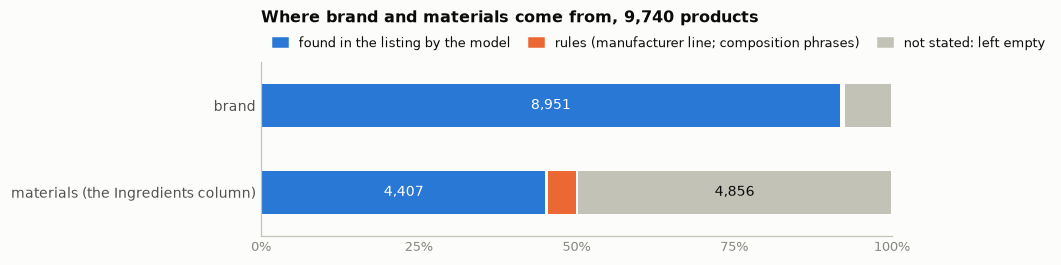

,brand,materials (the Ingredients column)
found in the listing by the model,8951,4407
not stated,748,4856
manufacturer line,41,0
rules,0,477


2,204 distinct brands; spellings of one brand given their most frequent form for 358 products


In [11]:
names = {"llm_extracted": "found in the listing by the model", "manufacturer_field": "manufacturer line", "listing_text_rules": "rules", "(none)": "not stated"}
colours = {"found in the listing by the model": BLUE, "manufacturer line": ORANGE, "rules": ORANGE, "not stated": GREY}
parts = {"brand": {names[k]: v for k, v in report["brand_source"].items()}, "materials (the Ingredients column)": {names[k]: v for k, v in report["ingredients_source"].items()}}

fig, ax = plt.subplots(figsize=(7.4, 2.05))
total = len(products)
for y, (field, counts) in enumerate(parts.items()):
    left = 0.0
    for part in ("found in the listing by the model", "manufacturer line", "rules", "not stated"):
        value = counts.get(part, 0)
        if not value:
            continue
        width = 100 * value / total
        ax.barh(y, width - 0.35, left=left + 0.175, height=0.5, color=colours[part], zorder=2)      # the gap separates the parts
        if width > 9:
            ax.text(left + width / 2, y, f"{value:,}", ha="center", va="center", color="#ffffff" if part != "not stated" else INK, fontsize=9)
        left += width
ax.set_yticks(range(len(parts)), list(parts))
ax.set_ylim(len(parts) - 0.5, -0.5)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.tick_params(length=0)
ax.set_title(f"Where brand and materials come from, {total:,} products", pad=26)
handles = [Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, GREY)]
ax.legend(handles, ["found in the listing by the model", "rules (manufacturer line; composition phrases)", "not stated: left empty"], ncol=3, frameon=False,
          loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1.2, columnspacing=1.4)
plt.show()
display(pd.DataFrame(parts).fillna(0).astype(int))
print(f"{products['brand'].nunique():,} distinct brands; spellings of one brand given their most frequent form for {report['brands_recased']} products")

So the model can choose among the listing's words and cannot add any. For 41 products the model named no brand that the
listing contains, and the manufacturer line of the specification gave one. Half the listings do not say what the product is
made of; for those the comparison table says "not stated".

## 6. Age: the field that could not be trusted

The specification carries a "manufacturer recommended age". It is wrong often enough to matter, and wrong in the dangerous
direction: it says months where years are meant.

In [12]:
knex = raw[raw["Product Url"].str.contains("B01B55BPB6", na=False)].iloc[0]
spec = cl.parse_spec(knex["Product Specification"])
print("title:      ", cl.clean_title(knex["Product Name"])[:110])
print("the field:  ", spec.get("manufacturerrecommendedage"), "->", cl.parse_age(spec.get("manufacturerrecommendedage")))
print("the title:  ", cl.parse_text_age(cl.clean_title(knex["Product Name"])))
row = products[products["sku"] == cl.asin_from_url(knex["Product Url"])].iloc[0]
print("in the catalog:", row["age_label"], "|", row["age_source"])

title:       K’NEX – Turbo Jet – 2-in-1 Building Set – 402 Pieces – Ages 7+ – Engineering Educational Toy
the field:   7months-15years -> (7, 180, '7 months to 15 years')
the title:   (84, None, 'Ages 7+')
in the catalog: 7 years and up | listing title: "Ages 7+"


Taken at its word, the field offers a 402-piece building set for a seven-month-old. Ages stated in the title and the
bullets are therefore parsed too and reconciled with the field (`cleaning.reconcile_age`): an age in the title wins, an
age in a bullet can only raise the minimum, and a title never moves a product below three years against the field. The
phrase that decided is kept in `age_source`.

In [13]:
age = report["age"]
display(pd.DataFrame([
    {"": "age from the field alone", "products": age["source"]["manufacturer field"]},
    {"": "age from the listing's text (the field was absent, or less strict)", "products": age["source"]["listing text"]},
    {"": "age from the title", "products": age["source"]["listing title"]},
    {"": "no age stated anywhere", "products": age["source"]["(none)"]},
    {"": "field contradicted by the listing's text by two years or more", "products": age["field_contradicted_by_listing_text"]},
]))
field_age = raw.assign(sku=raw["Product Url"].map(cl.asin_from_url)).drop_duplicates("sku").set_index("sku")["Product Specification"].map(
    lambda spec: cl.parse_spec(spec).get("manufacturerrecommendedage"))
conflicts = products[products["age_conflict"]].sample(5, random_state=3)
display(pd.DataFrame({"title": conflicts["title"].str.slice(0, 62), "the field says": conflicts["sku"].map(field_age),
                      "the listing says": conflicts["age_source"].str.replace(" (stricter than the manufacturer field)", "", regex=False), "kept": conflicts["age_label"]}))

,,products
0,age from the field alone,5440
1,"age from the listing's text (the field was absent, or less strict)",433
2,age from the title,385
3,no age stated anywhere,3482
4,field contradicted by the listing's text by two years or more,171


,title,the field says,the listing says,kept
3177,"V-Cube 5206457000159 3 Cube Toy, White/Multicolor",5months-8years,"listing text: ""ages 3 & up""",3 years to 8 years
4790,Toysmith Mini Sky Rocket,3yearsandup,"listing text: ""ages 6 years and up""",6 years and up
8351,AMAV Cotton Candy Party Building Kit. Your children will love,36months-6years,"listing text: ""ages 8 and up""",8 years and up
666,TeeTurtle Reversible Llama Mini - Black/Gray Plush Toys,6months-8years,"listing text: ""ages 6 and up""",6 years to 8 years
1157,"AMAV Toys Kids DIY Unicorn Painting Multicolor Kit, for Kids A",3months-8years,"listing title: ""Ages 3+""",3 years and up


The reconciliation can be wrong too, in either direction, and a table like the one above is how its errors are found. The
check below lists every product kept at twelve years or more although its field starts in months or its title speaks of
babies or toddlers. All ten are right (a drinking game whose field says "21 months to 3 years" is for ages 21 and older).
Until 12 November 2026 there was an eleventh: a pull toy for beginning walkers whose listing says "Ages 18 mos. +" had
been read as eighteen years, because the parser dropped the abbreviated unit with its period.

In [14]:
suspect = products[(products["age_min_months"] >= 144)
                   & (products["sku"].map(field_age).fillna("").str.match(r"^\d+\s*months?") | products["title"].str.contains(r"\b(?:toddler|baby|babies|infant)\b", case=False))]
display(pd.DataFrame({"title": suspect["title"].str.slice(0, 58), "the field says": suspect["sku"].map(field_age),
                      "the listing says": suspect["age_source"].str.replace(" (stricter than the manufacturer field)", "", regex=False), "kept": suspect["age_label"]}))
pull_toy = products[products["id"] == "AMZ-B002EI429Q"].iloc[0]
print(f"{pull_toy['title']}: {pull_toy['age_label']} ({pull_toy['age_source']}); returned for a child under three: {pull_toy['for_under_3']}")

,title,the field says,the listing says,kept
287,Discovery Layers of The Earth Geology Sand Dig Kit by Hori,6months-13years,"listing text: ""12 years & up""",12 years to 13 years
1835,"Rhode Island Novelty 48 Inch 7mm White Pearl Necklaces, Pa",36months-15years,"listing text: ""Ages 12+""",12 years to 15 years
2793,BePuzzled Original 3D Crystal Jigsaw Puzzle - Panda Bear &,12yearsandup,"listing title: ""Age 12 & Up""",12 years and up
3168,Poker Tiles Board Game,13monthsandup,"listing text: ""ages 12+""",12 years and up
3428,Hey! Play! Shoot The Shot Table Top Game-Drinking Game of,21months-3years,"listing text: ""ages 21 and older""",21 years and up
4066,Ubisoft Six Collection Figure - Montagne,36months-10years,"listing text: ""Ages 14+""",14 years and up
6517,The Jigsaw Puzzle Factory Elegant Interiors Afternoon Sunl,12months-8years,"listing title: ""Ages 12+""",12 years and up
6621,"Preiser 28176 Nursing Mother , Baby & Chair HO Model Figur",14yearsandup,manufacturer field,14 years and up
7173,Ubisoft Six Collection Figure – Ela,36months-10years,"listing text: ""Ages 14+""",14 years and up
8091,Codenames with One Night Ultimate Werewolf Bundle,8monthsandup,"listing text: ""Ages 14 and up""",14 years and up


Melissa & Doug Playful Puppy Wooden Pull Toy for Beginner Walkers: 18 months to 3 years (manufacturer field); returned for a child under three: True


**The under-three rule.** For a child younger than three the search returns only products whose own listing says they are
for babies or toddlers (`cleaning.explicitly_for_under_3`), never one with a small-parts, magnet, balloon or sharp-parts
warning, and never one without a stated age. Of the products whose minimum age is under three, about a third qualify:

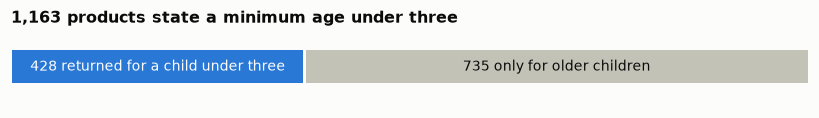

Four of the ones not returned for a child under three, and what their listings say:


,title,age_label,safety_flags
6954,Little Live Scruff-A-Luvs Plush Mystery Rescue Pet - Candy Floss,2 years to 15 years,[]
8534,"Precious Moments Pinocchio's Blue Fairy Doll, 7""",2 years to 8 years,[]
2060,The Old Lady Who Swallowed a Fly (Doll),3 months and up,[]
4554,"Watchover Voodoo 108010013 The Beautician Doll, Small, Multicolor",14 months to 8 years,[]


In [15]:
under3, admitted = age["min_age_under_3"], age["explicitly_for_under_3"]
segments([(f"{admitted} returned for a child under three", admitted, BLUE), (f"{under3 - admitted} only for older children", under3 - admitted, GREY)],
         f"{under3:,} products state a minimum age under three")

excluded = products[(products["age_min_months"] < 36) & ~products["for_under_3"]].sample(4, random_state=1)[["title", "age_label", "safety_flags"]]
excluded["title"] = excluded["title"].str.slice(0, 78)
print("Four of the ones not returned for a child under three, and what their listings say:")
display(excluded)

## 7. Safety warnings, claims and units

Warnings and claims are found by rules in the listing's text and specification, and are shown as what the listing says,
never as a finding of this project. A claim may be repeated in an answer only as "the listing says ...".

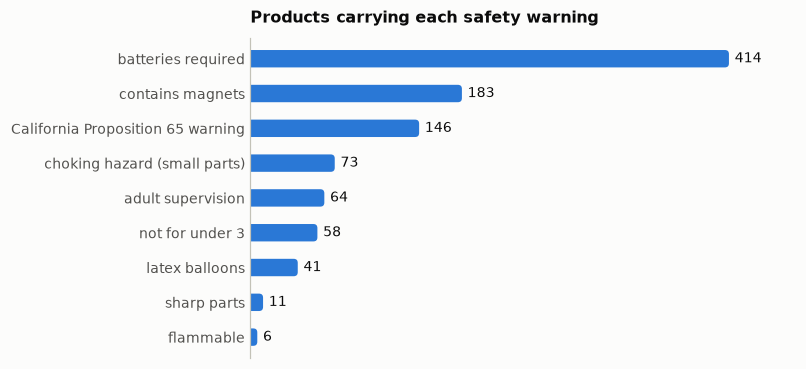

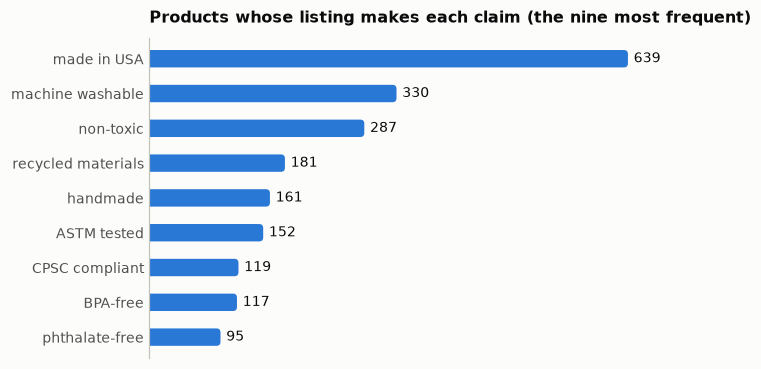

In [16]:
flag_names = {"batteries_required": "batteries required", "contains_magnets": "contains magnets", "prop65_warning": "California Proposition 65 warning",
              "choking_hazard": "choking hazard (small parts)", "adult_supervision": "adult supervision", "not_for_under_3": "not for under 3",
              "latex_balloons": "latex balloons", "sharp_parts": "sharp parts", "flammable": "flammable"}
flags = pd.Series(Counter(f for row in products["safety_flags"] for f in row)).rename(flag_names).sort_values(ascending=False)
claims = pd.Series(Counter(c for row in products["claims"] for c in row)).sort_values(ascending=False)
hbars(flags, "Products carrying each safety warning", width=6.4)
hbars(claims.head(9), "Products whose listing makes each claim (the nine most frequent)", width=6.4)

The assignment asks for normalised units so that prices can be compared fairly (`units.py`). A price per ounce is computed
only for products that are used up and state a net content; a toy's shipping weight is not a content.

In [17]:
chosen = ["Mission Models MMRC-011", "Tamiya TAM85026", "Champagne Flutes, Neon Pink", "Mini-Figurines Set - Farm", "Brackitz Inventor Building Toy 44-Piece", "1-2-3 Build It! Construction Crew"]
examples = pd.concat([products[products["title"].str.contains(text, regex=False)].head(1) for text in chosen])
examples = examples[["title", "price", "pack_count", "price_per_count", "content_amount", "content_unit", "price_per_oz", "piece_count"]]
display(examples.assign(title=examples["title"].str.slice(0, 72)).astype(object).where(examples.notna(), ""))
display(pd.DataFrame([
    {"": "a pack size in the title, so a price per item", "products": int(products["pack_count"].notna().sum())},
    {"": "a net content on something that is used up, so a price per ounce", "products": int(products["price_per_oz"].notna().sum())},
    {"": "a piece count of ten or more (puzzles, building sets)", "products": int(products["piece_count"].notna().sum())},
]))

,title,price,pack_count,price_per_count,content_amount,content_unit,price_per_oz,piece_count
5983,"Mission Models MMRC-011 Water-Based RC Paint, 2 oz Bottle, Aqua Blue",5.92,,,2.0,oz,2.96,
4083,"Tamiya TAM85026 85026 Lacquer Spray Paint, TS-26 Purple White - 100ml Sp",10.94,,,3.38,fl_oz,3.2367,
2785,"Party Essentials Hard Plastic Two Piece 5-Ounce Champagne Flutes, Neon P",10.89,10.0,1.089,,,,
7369,Building Block Mini-Figurines Set - Farm (Set of 3),6.46,3.0,2.1533,,,,
8891,Brackitz Inventor Building Toy 44-Piece Set – Award-Winning STEM Kids Bu,29.99,,,,,,44.0
8257,"Learning Resources 1-2-3 Build It! Construction Crew, Bulldozer, Digger,",22.25,,,,,,16.0


,,products
0,"a pack size in the title, so a price per item",601
1,"a net content on something that is used up, so a price per ounce",92
2,"a piece count of ten or more (puzzles, building sets)",529


The numbers are small because the catalog is mostly toys. Where pack sizes differ, the Planner asks for the unit price as
a comparison criterion and the table shows it.

## 8. One record, and what the index gets

The same product as in section 1, after ingestion. Every derived field has its provenance next to it.

In [18]:
record = ingest.load_products(ROOT / "data" / "processed" / "products.parquet").set_index("id").loc["AMZ-B000B9RHYC"]
groups = {
    "the eight required": ["title", "brand", "category", "price", "rating", "features", "ingredients"],
    "provenance": ["brand_source", "ingredients_source", "age_source", "snapshot_date"],
    "suitability and safety": ["age_label", "age_min_months", "age_max_months", "for_under_3", "safety_flags", "claims"],
    "for search and speech": ["product_type", "spoken_name", "category_path", "model_number"],
}
print("id  AMZ-B000B9RHYC   (what a citation shows)")
for group, fields in groups.items():
    print(f"\n{group}")
    for field in fields:
        print(f"    {field:<20} {str(record[field])[:118]}")

id  AMZ-B000B9RHYC   (what a citation shows)

the eight required
    title                Melissa & Doug Safari Wooden Chunky Puzzle (Preschool, Chunky Wooden Pieces, Full-Color Pictures, 8 Pieces, Great Gift
    brand                Melissa & Doug
    category             Toys & Games
    price                9.99
    rating               None
    features             ['8-PIECE WOODEN PUZZLE: The Melissa & Doug Safari Wooden Chunky Puzzle features 8 wooden, durable, easy-to-grasp piec
    ingredients          ['wood']

provenance
    brand_source         llm_extracted
    ingredients_source   llm_extracted
    age_source           listing title: "2, 3, and 4 Year Olds"
    snapshot_date        2020-01

suitability and safety
    age_label            2 years to 4 years
    age_min_months       24.0
    age_max_months       48.0
    for_under_3          True
    safety_flags         []
    claims               []

for search and speech
    product_type         wooden puzzle
    spoken_n

Each product becomes one document in the index, in three forms (`retrieval/documents.py`): the text that is embedded, the
text BM25 indexes, and the payload stored next to the vector, which is what filters test and what a search returns.

In [19]:
from voiceshop.retrieval import documents as docs

row = docs.row_to_dict({"id": "AMZ-B000B9RHYC", **record.to_dict()})
print("EMBEDDING TEXT\n   ", docs.embedding_text(row)[:420], "...\n")
print("LEXICAL TEXT (the title twice, so title words weigh more)\n   ", docs.lexical_text(row)[:200], "...\n")
payload = docs.payload(row)
print("PAYLOAD, the keys filters use\n   ", {k: payload[k] for k in ("price", "brand_norm", "category_norm", "has_age", "age_min_months", "age_max_months", "for_under_3", "ingredients_norm", "claims_norm", "safety_flags")})

EMBEDDING TEXT
    Melissa & Doug Safari Wooden Chunky Puzzle (Preschool, Chunky Wooden Pieces, Full-Color Pictures, 8 Pieces, Great Gift for Girls and Boys - Best for 2, 3, and 4 Year Olds). Type: wooden puzzle. Brand: Melissa & Doug. Category: Toys & Games > Puzzles > Pegged Puzzles. Recommended age: 2 years to 4 years. 8-PIECE WOODEN PUZZLE: The Melissa & Doug Safari Wooden Chunky Puzzle features 8 wooden, durable, easy-to-grasp pie ...

LEXICAL TEXT (the title twice, so title words weigh more)
    Melissa & Doug Safari Wooden Chunky Puzzle (Preschool, Chunky Wooden Pieces, Full-Color Pictures, 8 Pieces, Great Gift for Girls and Boys - Best for 2, 3, and 4 Year Olds) Melissa & Doug Safari Wooden ...

PAYLOAD, the keys filters use
    {'price': 9.99, 'brand_norm': 'melissa & doug', 'category_norm': ['toys & games', 'puzzles', 'pegged puzzles'], 'has_age': True, 'age_min_months': 24, 'age_max_months': 48, 'for_under_3': True, 'ingredients_norm': ['wood'], 'claims_norm': [], 'safety_fl

The embedding model reads at most 256 tokens of that text. The title, type, brand, category and age come first and always
fit; what can be cut off is the end of the description, which the lexical text keeps for longer.

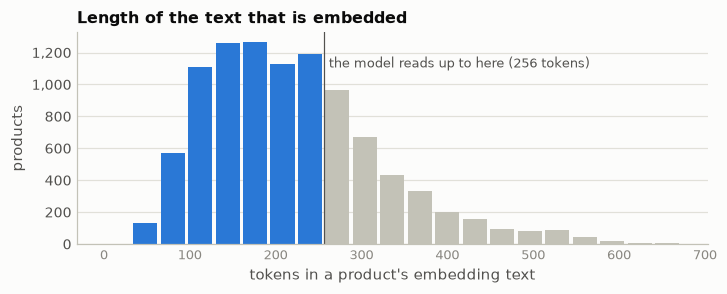

median 206 tokens; 69% of products fit whole; the rest lose the end of their description


In [20]:
tokenizer_file = ROOT / "models" / "embeddings" / "bge-small-en-v1.5" / "tokenizer.json"
if tokenizer_file.exists():
    from tokenizers import Tokenizer

    tokenizer = Tokenizer.from_file(str(tokenizer_file))
    tokenizer.no_truncation()
    full = ingest.load_products(ROOT / "data" / "processed" / "products.parquet")
    texts = [docs.embedding_text(docs.row_to_dict(r)) for r in full.to_dict(orient="records")]
    lengths = np.array([len(e.ids) for e in tokenizer.encode_batch(texts)])
    fig, ax = plt.subplots(figsize=(7.4, 2.5))
    counts, edges = np.histogram(lengths, bins=np.arange(0, 700, 32))
    ax.bar(edges[:-1] + 16, counts, width=28, color=[BLUE if e < 256 else GREY for e in edges[:-1]], zorder=2)
    ax.axvline(256, color=SECONDARY, linewidth=0.8)
    ax.text(262, counts.max() * 0.93, "the model reads up to here (256 tokens)", color=SECONDARY, fontsize=8.5, va="top")
    ax.set_xlabel("tokens in a product's embedding text")
    ax.set_ylabel("products")
    ax.yaxis.grid(True)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.set_title("Length of the text that is embedded")
    plt.show()
    print(f"median {int(np.median(lengths))} tokens; {100 * (lengths <= 256).mean():.0f}% of products fit whole; the rest lose the end of their description")
else:
    print("The embedding model's tokenizer is not on this machine (scripts/bootstrap_mac.sh downloads it); the chart of text lengths is skipped.")

## 9. A small index, searched

The real index is built by `voiceshop index` over all products and searched through the `rag.search` tool. To show the
mechanics here without touching it, the cell below builds a throw-away index in memory over the catalog's puzzles and the
products labelled for children under three, with the same code (`SearchEngine.in_memory`), and runs three searches: one
whose constraints can all be met, one for a child under three, and one that asks for more than the catalog has.

In [21]:
from voiceshop.config import get_settings
from voiceshop.retrieval.embedder import HashingEmbedder, build_embedder
from voiceshop.retrieval.engine import SearchEngine
from voiceshop.retrieval.filters import SearchFilters

full = ingest.load_products(ROOT / "data" / "processed" / "products.parquet")
subset = full[full["category_path"].map(lambda p: "Puzzles" in list(p)) | full["for_under_3"]]
try:
    embedder = build_embedder(get_settings())               # the real sentence encoder, if its files are on this machine
except Exception:
    embedder = HashingEmbedder()                            # no model files: word hashing, enough to show filters and ranking by words
engine = SearchEngine.in_memory(subset.to_dict(orient="records"), embedder)
print(f"{len(subset):,} products indexed in memory with {embedder.name}\n")


def search(query: str, **filters) -> None:
    result = engine.search(query, SearchFilters(**filters), top_k=3)
    print(f"{query!r} {filters}\n    {result.strict_matches} products meet every constraint; loosened: {result.relaxed or 'nothing'}; applied automatically: {'the under-three rule' if result.safety_rules else 'nothing'}")
    for hit in result.results:
        print(f"    ${hit.price:>6.2f}  {hit.title[:66]:<66}  {hit.age_label or 'no age stated'}  {'; '.join(hit.constraint_notes)}")
    print()


search("wooden puzzle", price_max=20, age_years=3, materials=["wood"])
search("stacking toy", age_years=1.5, price_max=20)
search("wooden puzzle", price_max=3, age_years=4, materials=["wood"], brand="Melissa & Doug")

774 products indexed in memory with BAAI/bge-small-en-v1.5

'wooden puzzle' {'price_max': 20, 'age_years': 3, 'materials': ['wood']}
    37 products meet every constraint; loosened: nothing; applied automatically: nothing
    $  7.99  Melissa & Doug Barnyard Wooden Jigsaw Puzzle (24 pcs)               3 years to 5 years  
    $  9.99  Melissa & Doug Safari Wooden Chunky Puzzle (Preschool, Chunky Wood  2 years to 4 years  
    $ 14.99  Janod 3 Level Puzzle - Turtle Puzzle                                2 years to 4 years  

'stacking toy' {'age_years': 1.5, 'price_max': 20}
    215 products meet every constraint; loosened: nothing; applied automatically: the under-three rule
    $ 15.19  VTech Stack and Sing Rings                                          6 months to 3 years  
    $  5.99  Ambi Toys, Building Beakers                                         10 months to 3 years  
    $ 19.99  Very Hungry Caterpillar Wood Stacker                                6 months and up  

'wooden pu

The third search asks for more than the catalog has: no Melissa & Doug wooden puzzle costs \$3. The search then loosens
constraints in a fixed order, the budget last, and every result says which constraint it misses. For a child under three
nothing is ever loosened. How this was measured on the full index is in [docs/retrieval.md](../docs/retrieval.md).

## What is not in the data

- **Ratings and reviews.** None. `rating` is empty for every catalog product; a rating appears in an answer only when a live web listing states one.
- **Stock and current prices.** The catalog is a January 2020 snapshot. Only a live result can say what something costs today or whether it can be bought.
- **A brand for 748 products, materials for 4,856.** Left empty, and shown as "not stated".